In [1]:
#pip install ucimlrepo

In [1]:
import pandas as pd
import numpy as np
np.set_printoptions(legacy="1.25")

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

In [3]:
from ucimlrepo import fetch_ucirepo 

In [39]:
from sklearn.metrics import roc_auc_score, mutual_info_score

In [4]:
from sklearn.model_selection import train_test_split

In [5]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

In [6]:
bank_marketing = fetch_ucirepo(id=222)

In [7]:
X = bank_marketing.data.features 
y = bank_marketing.data.targets 

In [8]:
X

,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome
0,58,management,married,tertiary,no,2143,yes,no,NaN,5,may,261,1,-1,0,NaN
1,44,technician,single,secondary,no,29,yes,no,NaN,5,may,151,1,-1,0,NaN
2,33,entrepreneur,married,secondary,no,2,yes,yes,NaN,5,may,76,1,-1,0,NaN
3,47,blue-collar,married,NaN,no,1506,yes,no,NaN,5,may,92,1,-1,0,NaN
4,33,NaN,single,NaN,no,1,no,no,NaN,5,may,198,1,-1,0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45206,51,technician,married,tertiary,no,825,no,no,cellular,17,nov,977,3,-1,0,NaN
45207,71,retired,divorced,primary,no,1729,no,no,cellular,17,nov,456,2,-1,0,NaN
45208,72,retired,married,secondary,no,5715,no,no,cellular,17,nov,1127,5,184,3,success
45209,57,blue-collar,married,secondary,no,668,no,no,telephone,17,nov,508,4,-1,0,NaN


In [9]:
y

,y
0,no
1,no
2,no
3,no
4,no
...,...
45206,yes
45207,yes
45208,yes
45209,no


**EDA**

In [10]:
X.dtypes

age            int64
job              str
marital          str
education        str
default          str
balance        int64
housing          str
loan             str
contact          str
day_of_week    int64
month            str
duration       int64
campaign       int64
pdays          int64
previous       int64
poutcome         str
dtype: object

In [11]:
X.tail().T

,45206,45207,45208,45209,45210
age,51,71,72,57,37
job,technician,retired,retired,blue-collar,entrepreneur
marital,married,divorced,married,married,married
education,tertiary,primary,secondary,secondary,secondary
default,no,no,no,no,no
balance,825,1729,5715,668,2971
housing,no,no,no,no,no
loan,no,no,no,no,no
contact,cellular,cellular,cellular,telephone,cellular
day_of_week,17,17,17,17,17


In [12]:
X.columns

Index(['age', 'job', 'marital', 'education', 'default', 'balance', 'housing',
       'loan', 'contact', 'day_of_week', 'month', 'duration', 'campaign',
       'pdays', 'previous', 'poutcome'],
      dtype='str')

In [ ]:
strings = list(X.dtypes[X.dtypes == 'str'].index)
for s in strings:
    X[s] = X[s].str.lower().str.replace(' ', '_')

In [13]:
X.isnull().sum()

age                0
job              288
marital            0
education       1857
default            0
balance            0
housing            0
loan               0
contact        13020
day_of_week        0
month              0
duration           0
campaign           0
pdays              0
previous           0
poutcome       36959
dtype: int64

Only 4 categorical columns have nulls. So fill them with 'NA' for all 4 columns.

In [63]:
nulls = list(X.columns[X.isnull().any()])
nulls

['job', 'education', 'contact', 'poutcome']

In [64]:
for n in nulls:
    X[n] = X[n].fillna('NA')

In [65]:
X.isnull().any()

age            False
job            False
marital        False
education      False
default        False
balance        False
housing        False
loan           False
contact        False
day_of_week    False
month          False
duration       False
campaign       False
pdays          False
previous       False
poutcome       False
convert        False
dtype: bool

In [14]:
y.isnull().sum()

y    0
dtype: int64

In [15]:
y = (y == 'yes').astype(int)

In [16]:
y.head()

,y
0,0
1,0
2,0
3,0
4,0


In [112]:
global_conv = y.mean()
global_conv

y    0.116985
dtype: float64

In [35]:
X.campaign.value_counts(normalize=True)

campaign
1     0.388047
2     0.276592
3     0.122116
4     0.077901
5     0.039017
6     0.028555
7     0.016257
8     0.011944
9     0.007233
10    0.005884
11    0.004446
12    0.003428
13    0.002942
14    0.002057
15    0.001858
16    0.001747
17    0.001526
18    0.001128
19    0.000973
20    0.000951
21    0.000774
22    0.000509
25    0.000487
23    0.000487
24    0.000442
28    0.000354
29    0.000354
26    0.000288
31    0.000265
27    0.000221
32    0.000199
30    0.000177
33    0.000133
34    0.000111
35    0.000088
36    0.000088
43    0.000066
38    0.000066
41    0.000044
50    0.000044
37    0.000044
51    0.000022
63    0.000022
55    0.000022
46    0.000022
58    0.000022
39    0.000022
44    0.000022
Name: proportion, dtype: float64

<Axes: xlabel='campaign', ylabel='Count'>

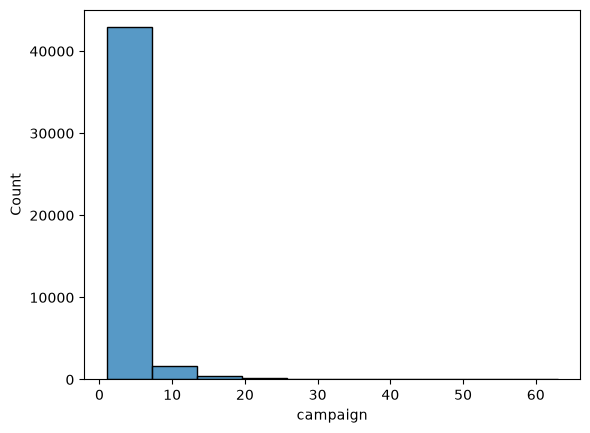

In [34]:
sns.histplot(X['campaign'],bins=10)

In [37]:
X.previous.value_counts(normalize=True)

previous
0      0.817367
1      0.061313
2      0.046582
3      0.025259
4      0.015793
5      0.010152
6      0.006127
7      0.004534
8      0.002853
9      0.002035
10     0.001482
11     0.001438
12     0.000973
13     0.000841
15     0.000442
14     0.000420
17     0.000332
16     0.000288
19     0.000243
20     0.000177
23     0.000177
18     0.000133
22     0.000133
27     0.000111
24     0.000111
21     0.000088
25     0.000088
29     0.000088
30     0.000066
26     0.000044
37     0.000044
38     0.000044
28     0.000044
51     0.000022
275    0.000022
58     0.000022
32     0.000022
40     0.000022
55     0.000022
35     0.000022
41     0.000022
Name: proportion, dtype: float64

In [38]:
X.pdays.value_counts(normalize=True)

pdays
-1      0.817367
 182    0.003694
 92     0.003251
 91     0.002787
 183    0.002787
          ...   
 541    0.000022
 543    0.000022
 871    0.000022
 550    0.000022
 530    0.000022
Name: proportion, Length: 559, dtype: float64

In [84]:
X['pdays'].describe()

count    45211.000000
mean        40.197828
std        100.128746
min         -1.000000
25%         -1.000000
50%         -1.000000
75%         -1.000000
max        871.000000
Name: pdays, dtype: float64

-1 refers to clients not contacted before. But since this is a numerical value, -1 can give a wrong indication as the most recent/ future contact. It would be better to have a high number comparatively(999) and a separate column to show whether a client was contacted before or not.

In [88]:
X['contacted_before'] = (X['pdays']!=-1).astype(int)

In [90]:
X['pdays'] = X['pdays'].replace(-1, 999)

In [98]:
X.day_of_week.describe()

count    45211.000000
mean        15.806419
std          8.322476
min          1.000000
25%          8.000000
50%         16.000000
75%         21.000000
max         31.000000
Name: day_of_week, dtype: float64

Day of week shows values 1-31 which seems like a day of the month. The column needs to be renamed to day_of_month.

In [101]:
X.rename(columns = {'day_of_week':'day_of_month'}, inplace=True)

In [105]:
categorical = ['job', 'marital', 'education', 'default', 'housing', 
               'loan', 'contact', 'month','poutcome', 'contacted_before']
numerical = ['age', 'balance', 'day_of_month', 'duration', 'campaign', 'pdays', 'previous']

In [106]:
def roc_auc(c):
    return roc_auc_score(y, c)

In [107]:
auc_scores = X[numerical].apply(roc_auc)
auc_scores.sort_values(ascending=False)

duration        0.807596
previous        0.602303
balance         0.590061
age             0.492145
day_of_month    0.473480
campaign        0.427666
pdays           0.392153
dtype: float64

Duration has a very high impact on the outcome. This is very understandable given that interested clients tend to continue the conversations longer.

In [108]:
def mi_score(c):
    return(mutual_info_score(y.y, c))

In [109]:
mi_scores = X[categorical].apply(mi_score)
mi_scores.sort_values(ascending=False)

poutcome            0.029397
month               0.024351
contact             0.013627
contacted_before    0.011980
housing             0.009654
job                 0.008264
loan                0.002630
education           0.002598
marital             0.002101
default             0.000294
dtype: float64

poutcome, month and contact variables have the stronger relation to the outcome then the remaining variables. default is the lowest impacting variable. 

In [110]:
X['convert'] = y

In [21]:
X.tail().T

,45206,45207,45208,45209,45210
age,51,71,72,57,37
job,technician,retired,retired,blue-collar,entrepreneur
marital,married,divorced,married,married,married
education,tertiary,primary,secondary,secondary,secondary
default,no,no,no,no,no
balance,825,1729,5715,668,2971
housing,no,no,no,no,no
loan,no,no,no,no,no
contact,cellular,cellular,cellular,telephone,cellular
day_of_week,17,17,17,17,17


Splitting the dataset into train, val and test sets.

In [50]:
X_full_train, X_test = train_test_split(X, test_size = 0.2, random_state=1)
X_train, X_val = train_test_split(X_full_train, test_size = 0.25, random_state = 1)
X_full_train.shape, X_train.shape, X_val.shape, X_test.shape

((36168, 17), (27126, 17), (9042, 17), (9043, 17))

In [46]:
def train(df_train, y_train, C):

    dicts = df_train[categorical + numerical].to_dict(orient='records')
    dv = DictVectorizer(sparse = False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(C=C, max_iter=1000)
    model.fit(X_train)

    return dv, model

In [47]:
def predict(df, dv, model):

    dicts = df[categorical+numerical].to_dict(orient='records')
    
    X = dv.transform(dicts)
    
    y_pred = model.predict_proba(X)[:,1]

    return y_pred